# Map of Catalonia by regions: forest hectares burned (2011-2024)
## Jesús Ruiz Angorrilla
In this notebook we join the fires table with the comarca outlines and map the total forest area burned in each comarca between 2011 and 2024.

**Data** (both in `../data/`, see the README there for sources and licences):
- Forest fires in Catalonia, 2011-2024 (CSV): one row per fire, with its comarca code and the hectares burned.
- Comarca outlines of Catalonia (ICGC, 1:250,000, JSON).

**Steps**
1. Read the fires table and sum the forest hectares burned (`HAFORESTAL`) per comarca.
2. Read the outlines and join both tables by comarca code.
3. Draw a map with a colour scale of the burned hectares per comarca.

**Output**: the map is saved in `"../figures/Jesus/fires_map_regions.png"`.

## 0) Libraries and paths

In [1]:
import pandas as pd                
import geopandas as gpd            
import matplotlib.pyplot as plt  
from matplotlib.patches import Patch
import os
from matplotlib.colors import LogNorm
from PIL import Image

## 1) Read and prepare the fires table

In [2]:
# Read the CSV; numbers look like "5.621,80", so the dot separates thousands and the comma marks decimals
fires = pd.read_csv("../data/raw/Incendis_forestals_a_Catalunya._Anys_2011-2024_20261116.csv",decimal=",", thousands=".",)

# The comarca code in the CSV is a number without leading zero (8), but in the map it is text with two digits ("08")
# I turn it into text and pad it with zeros on the left until it has 2 digits
fires["code"] = fires["CODI COMARCA"].astype(str).str.zfill(2)

# Each row is one fire, but I want one total per comarca
# Group by comarca and add up the burned forest hectares (column HAFORESTAL)
total = fires.groupby("code")["HAFORESTAL"].sum().reset_index()

# Give the summed column a clearer name
total = total.rename(columns={"HAFORESTAL": "ha_burned"})


## 2) Read the map and join it with the data

In [3]:
# Read the file with the comarca outlines
map_com = gpd.read_file(("../data/raw/divisions-administratives-v2r1-comarques-250000-20250730.json"))

# Convert to Catalonia's coordinate system (EPSG:25831) so the map is not distorted
map_com = map_com.to_crs(25831)

# Join the map with my totals using the comarca code 
# how="left" keeps every comarca even if it has no data; validate prevents duplicated rows
map_com = map_com.merge(total, left_on="CODICOMAR", right_on="code", how="left", validate="one_to_one")

## 3) Draw the map

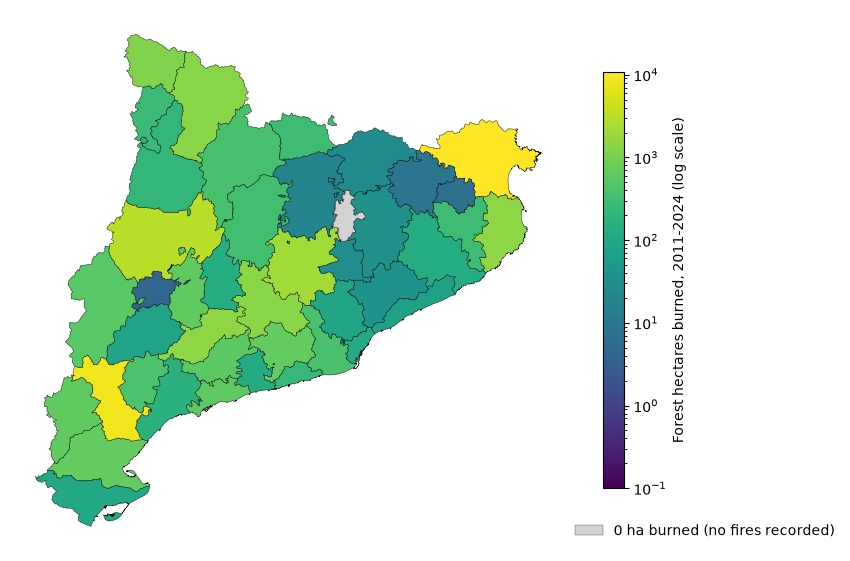

In [4]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(9, 9))

# Draw the map, colouring each comarca by its burned hectares
map_com.plot(column="ha_burned", cmap="viridis", norm=LogNorm(vmin=0.1, vmax=map_com["ha_burned"].max()), legend=True, 
             legend_kwds={"label": "Forest hectares burned, 2011-2024 (log scale)", "shrink": 0.6},
             missing_kwds={"color": "lightgrey"}, edgecolor="black", linewidth=0.3, ax=ax,)
grey_patch = Patch(facecolor="lightgrey", edgecolor="black", linewidth=0.2, label="0 ha burned (no fires recorded)")
ax.legend(handles=[grey_patch], loc="lower right", bbox_to_anchor=(1.5, 0), frameon=False)
ax.set_axis_off()

fig.savefig("../figures/Jesus/fires_map_regions.png", dpi=200, bbox_inches="tight")

plt.show()

This map shows the same data as the municipality map, but grouped by comarca. It is useful if the funding or financial support for fire prevention were assigned at a larger territorial level (by comarca) instead of by municipality: in that case this map lets us compare directly which comarcas have suffered the most and should receive more resources, without having to add up the municipalities one by one. As in the previous map, the colour scale is logarithmic and the comarcas in light grey had no burned forest area (0 ha).